# 10 - Overfitting Check (video stroke classifier)

Self-contained diagnostic. It **reuses the exact same split** as notebook 01
(same SEED, same group-split by match), loads the saved `model23/video_model.pth`,
and evaluates it on **train / val / test**.

A small **train -> test gap** means the model generalises (not overfitting).
A large gap (train high, test low) is the signature of overfitting.

Run cells top to bottom. No retraining - inference only.

In [1]:
import torch, os
assert torch.cuda.is_available(), 'No GPU active. Runtime > Change runtime type > GPU, then re-run.'
print('GPU:', torch.cuda.get_device_name(0))
from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
print('Drive ready:', os.path.isdir('/content/drive/MyDrive'))
!pip install -q opencv-python-headless seaborn gdown

GPU: NVIDIA L4
Drive ready: True


In [2]:
import os
CLASSES = [
    (0, 'Short Serve', '00_Short Serve'),
    (1, 'Lift',        '02_Lift'),
    (2, 'Clear',       '12_Clear'),
    (3, 'Drop Shot',   '05_Drop Shot'),
    (4, 'Smash',       '14_Smash'),
]
NUM_CLASSES   = len(CLASSES)
DISPLAY_NAMES = [c[1] for c in CLASSES]
CLASS_FOLDERS = [c[2] for c in CLASSES]
FOLDER_TO_ID  = {c[2]: c[0] for c in CLASSES}

DRIVE       = '/content/drive/MyDrive/BadmintonFYP'
MODELS      = DRIVE + '/model23'
CKPT        = MODELS + '/video_model.pth'
DATASET_ZIP = DRIVE + '/DATASET2.zip'

NUM_FRAMES = 16
IMG        = 224
BATCH      = 8
SEED       = 42
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
print('Checkpoint:', CKPT, '| exists:', os.path.exists(CKPT))

Checkpoint: /content/drive/MyDrive/BadmintonFYP/model23/video_model.pth | exists: True


In [3]:
import glob, zipfile, shutil
EXTRACT_DIR    = '/content/data'
GDRIVE_FILE_ID = ''

def has_all(d):
    return os.path.isdir(d) and all(os.path.isdir(os.path.join(d, f)) for f in CLASS_FOLDERS)
def find_root(base):
    for c in [base] + sorted(glob.glob(base + '/*')) + sorted(glob.glob(base + '/*/*')):
        if os.path.isdir(c) and any(os.path.isdir(os.path.join(c, f)) for f in CLASS_FOLDERS):
            return c
    return None

root = find_root(EXTRACT_DIR)
if root is None or not has_all(root):
    zips = []
    for pat in (DATASET_ZIP, DRIVE + '/*.zip', '/content/drive/MyDrive/*.zip', '/content/*.zip'):
        zips += glob.glob(pat)
    zips = sorted(set(z for z in zips if os.path.exists(z)), key=lambda z: (0 if 'dataset' in z.lower() else 1, len(z)))
    if not zips:
        try:
            import gdown
            out = '/content/DATASET2.zip'
            if not os.path.exists(out):
                print('Downloading DATASET2.zip by file ID...')
                gdown.download(id=GDRIVE_FILE_ID, output=out, quiet=False)
            if os.path.exists(out) and os.path.getsize(out) > 1000000:
                zips = [out]
        except Exception as e:
            print('gdown failed:', e)
    if zips:
        print('Extracting', zips[0])
        if os.path.exists(EXTRACT_DIR): shutil.rmtree(EXTRACT_DIR)
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall(EXTRACT_DIR)
        root = find_root(EXTRACT_DIR)

DATASET_DIR = root or EXTRACT_DIR
print('Using DATASET_DIR =', DATASET_DIR)

Extracting /content/drive/MyDrive/BadmintonFYP/DATASET2.zip
Using DATASET_DIR = /content/data


In [4]:
import numpy as np, pandas as pd, cv2
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report

np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def load_video_frames(path, num_frames=NUM_FRAMES):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise ValueError('cannot open ' + path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0:
        cap.release(); raise ValueError('0 frames ' + path)
    idxs = np.linspace(0, total - 1, num_frames, dtype=int)
    frames = []
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, fr = cap.read()
        if ok:
            frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        elif frames:
            frames.append(frames[-1].copy())
    cap.release()
    while len(frames) < num_frames:
        frames.append(frames[-1].copy() if frames else np.zeros((IMG, IMG, 3), np.uint8))
    return frames[:num_frames]

def letterbox(img, size=IMG):
    h, w = img.shape[:2]
    s = min(size / h, size / w)
    nh, nw = int(h * s), int(w * s)
    r = cv2.resize(img, (nw, nh))
    canvas = np.zeros((size, size, 3), np.uint8)
    y, x = (size - nh) // 2, (size - nw) // 2
    canvas[y:y+nh, x:x+nw] = r
    return canvas

_norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
def preprocess_frames(frames, size=IMG):
    out = []
    for fr in frames:
        fr = letterbox(fr, size).astype(np.float32) / 255.0
        out.append(_norm(torch.from_numpy(fr).permute(2, 0, 1)))
    return torch.stack(out)

class VideoClipDataset(Dataset):
    def __init__(self, df): self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        try:
            return preprocess_frames(load_video_frames(row.file_path)), int(row.label_id)
        except Exception as e:
            print('skip', row.file_path, e)
            return torch.zeros(NUM_FRAMES, 3, IMG, IMG), int(row.label_id)

def build_index(root):
    rows = []
    for folder in CLASS_FOLDERS:
        p = os.path.join(root, folder)
        if not os.path.isdir(p):
            print('missing folder', p); continue
        lid = FOLDER_TO_ID[folder]
        for fn in os.listdir(p):
            if fn.lower().endswith('.mp4'):
                gid = fn.split('_dataset_set')[0] if '_dataset_set' in fn else fn[:19]
                rows.append({'file_path': os.path.join(p, fn), 'label_id': lid, 'label_name': folder, 'group_id': gid})
    return pd.DataFrame(rows)

def group_split(df, val=0.15, test=0.15, seed=SEED):
    g1 = GroupShuffleSplit(n_splits=1, test_size=val + test, random_state=seed)
    tr, tmp = next(g1.split(df, groups=df.group_id))
    dtr, dtmp = df.iloc[tr].reset_index(drop=True), df.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test / (val + test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.group_id))
    dva, dte = dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)
    assert not (set(dtr.group_id) & set(dva.group_id)) and not (set(dtr.group_id) & set(dte.group_id))
    return dtr, dva, dte

class TemporalPoolingResNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        base = models.resnet18(weights=None)
        self.features = nn.Sequential(*list(base.children())[:-1])
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.view(b * t, c, h, w)
        x = self.features(x).view(b, t, 512).mean(dim=1)
        return self.fc(x)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    P, L = [], []
    for x, y in loader:
        x = x.to(DEVICE)
        out = model(x)
        P += out.argmax(1).cpu().tolist(); L += y.tolist()
    return accuracy_score(L, P), f1_score(L, P, average='macro'), P, L

print('defs ready')

defs ready


clips: 4218 | train 2828 val 658 test 732
match overlap train&test: set() (empty = no leakage)
Loaded model: /content/drive/MyDrive/BadmintonFYP/model23/video_model.pth
skip /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4 cannot open /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4

SPLIT     accuracy   macro-F1
train      0.988      0.989
val        0.924      0.923
test       0.951      0.947

train - test macro-F1 gap = 0.041
=> HEALTHY: train and test are close. The model generalises - not overfitting.


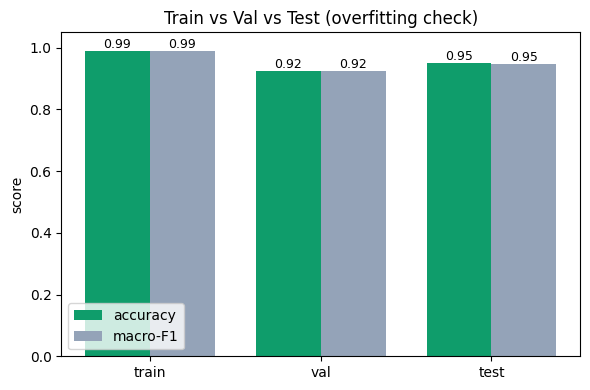

Saved chart to /content/drive/MyDrive/BadmintonFYP/model23/overfitting_check.png


In [5]:
import matplotlib.pyplot as plt

df = build_index(DATASET_DIR)
assert len(df) > 0, 'No clips found - check DATASET_DIR.'
df_train, df_val, df_test = group_split(df)
print('clips:', len(df), '| train', len(df_train), 'val', len(df_val), 'test', len(df_test))
print('match overlap train&test:', set(df_train.group_id) & set(df_test.group_id), '(empty = no leakage)')

model = TemporalPoolingResNet().to(DEVICE)
assert os.path.exists(CKPT), 'Checkpoint not found: ' + CKPT
model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
print('Loaded model:', CKPT)

tr_acc, tr_f1, _, _   = evaluate(model, DataLoader(VideoClipDataset(df_train), batch_size=BATCH, num_workers=2))
va_acc, va_f1, _, _   = evaluate(model, DataLoader(VideoClipDataset(df_val),   batch_size=BATCH, num_workers=2))
te_acc, te_f1, tP, tL = evaluate(model, DataLoader(VideoClipDataset(df_test),  batch_size=BATCH, num_workers=2))

print()
print('SPLIT     accuracy   macro-F1')
print('train      %.3f      %.3f' % (tr_acc, tr_f1))
print('val        %.3f      %.3f' % (va_acc, va_f1))
print('test       %.3f      %.3f' % (te_acc, te_f1))

gap = tr_f1 - te_f1
print()
print('train - test macro-F1 gap = %.3f' % gap)
if gap < 0.05:
    print('=> HEALTHY: train and test are close. The model generalises - not overfitting.')
elif gap < 0.12:
    print('=> MILD: small gap, normal for fine-tuning; early stopping keeps it in check.')
else:
    print('=> OVERFITTING: large gap. Consider more data, augmentation or regularisation.')

labels = ['train', 'val', 'test']
accs = [tr_acc, va_acc, te_acc]; f1s = [tr_f1, va_f1, te_f1]
xs = range(len(labels)); w = 0.38
plt.figure(figsize=(6, 4))
plt.bar([i - w/2 for i in xs], accs, width=w, label='accuracy', color='#0f9d6b')
plt.bar([i + w/2 for i in xs], f1s, width=w, label='macro-F1', color='#94a3b8')
plt.xticks(list(xs), labels); plt.ylim(0, 1.05); plt.ylabel('score')
plt.title('Train vs Val vs Test (overfitting check)'); plt.legend()
for i in xs:
    plt.text(i - w/2, accs[i] + 0.01, '%.2f' % accs[i], ha='center', fontsize=9)
    plt.text(i + w/2, f1s[i] + 0.01, '%.2f' % f1s[i], ha='center', fontsize=9)
plt.tight_layout(); plt.savefig(MODELS + '/overfitting_check.png', dpi=150); plt.show()
print('Saved chart to', MODELS + '/overfitting_check.png')